# Chaînes 13 — Le spin, l'hélicité et le groupe spin-c

Chapitre 52 du compendium *Chain Theory* (Wissner-Gross, 2026, preprint non relu), sections 57 et 58. Trois résultats : le **Théorème 57.1** (standing: theorem) — au premier corps qui diffère, le label des bouts ouverts se re-contre par une seconde route ; l'**Open result 57.2** (standing: an open result) — le spin lu des seuls bouts ouverts atteint le nom à six corps sur neuf, et l'objet qui parte est nommé ; et le **Théorème 58.1** (standing: theorem) — le groupe d'identification de la paire $(2,2)$ **est** le groupe que la littérature nomme spin-c, de bout en bout de la comparaison.

Le patron de la série tient : **Mesuré** ce que nos fractions rejouent, **Cité** toute la chaîne dérivative du source, **Ouvert** ce qu'il ne prouve pas.

## Le cadre : le label que la littérature appelle spin

« Beyond the boost, the next chapter reads the label that the literature calls spin » (p. 152) — la promesse tenue du chapitre précédent. Le geste : lister les **copies qubit ouvertes** des lignes de fin d'une toile, avec leur lettre ket ou bra ; le **compte signé** $S = k - l$ et l'**ensemble des labels** en sortent ; la **règle du label**, posée à trois lectures (le plus bas, le plus bas non nul, le plus grand), y lit le spin doublé $2s$. À la lecture fermée, le contenu est le triplet aux mots W, Z, gluon et photon, aucun au mot Higgs, un doublet aux neuf corps de chaîne : le spin est la moitié de tout corps, l'un de tout porteur vectoriel, le zéro du Higgs (conditionnel aux lectures posées — cité, p. 153-154).

## §57 — Théorème 57.1 : le spin au corps qui diffère

« At the first body at which the twice-spin read from the open qubit ends alone parted from the name [...] the label content re-built at a second route from its open ends alone, the weight route with no pairwise Clebsch-Gordan rule, reads zero and two at four states with the multiplicities one and one, equal to the rule at that body at every one of its three readings » (p. 153). Le corps qui diffère : une toile de **trois sites et deux liens au genre (2,3)**, une fin ket ouverte et une fin bra ouverte de dimension deux, les espaces de flèche des deux liens à la dimension six chacun, ket $\otimes$ bra — quatre états. La **table décisive est re-dérivée en Lean** (cité). Standing: theorem.

In [1]:
# Arithmetique exacte : un complexe est une paire de Fractions (re, im).
from fractions import Fraction as F

def cadd(a, b): return (a[0] + b[0], a[1] + b[1])
def csub(a, b): return (a[0] - b[0], a[1] - b[1])
def cmul(a, b): return (a[0] * b[0] - a[1] * b[1], a[0] * b[1] + a[1] * b[0])
def cscale(q, a): return (q * a[0], q * a[1])
def cconj(a): return (a[0], -a[1])
Z, U, CI = (F(0), F(0)), (F(1), F(0)), (F(0), F(1))
def csum(xs):
    s = Z
    for x in xs:
        s = cadd(s, x)
    return s

def cstr(a):
    re, im = a
    if re == 0 and im == 0: return "0"
    parts = []
    if re != 0: parts.append(str(re))
    if im != 0:
        sign = "-" if im < 0 else ("+" if parts else "")
        mag = abs(im)
        parts.append(sign + ("" if mag == 1 else str(mag)) + "i")
    return "".join(parts)

def meye(n): return [[(F(int(i == j)), F(0)) for j in range(n)] for i in range(n)]
def mzeros(n): return [[Z for _ in range(n)] for _ in range(n)]
def madd(A, B): return [[cadd(A[i][j], B[i][j]) for j in range(len(A))] for i in range(len(A))]
def msub(A, B): return [[csub(A[i][j], B[i][j]) for j in range(len(A))] for i in range(len(A))]
def mmul(A, B):
    n, m, K = len(A), len(B[0]), len(B)
    out = [[Z for _ in range(m)] for _ in range(n)]
    for i in range(n):
        for j in range(m):
            s = Z
            for t in range(K):
                s = cadd(s, cmul(A[i][t], B[t][j]))
            out[i][j] = s
    return out
def mscale(q, A): return [[cscale(q, A[i][j]) for j in range(len(A))] for i in range(len(A))]
def mT(A): return [[A[j][i] for j in range(len(A))] for i in range(len(A))]
def mdag(A): return [[cconj(A[j][i]) for j in range(len(A))] for i in range(len(A))]
def mcomm(A, B): return msub(mmul(A, B), mmul(B, A))
def meq(A, B):
    # Egalite ligne a ligne : valable pour matrices (listes de rangees) et vecteurs (listes de paires).
    return len(A) == len(B) and all(ra == rb for ra, rb in zip(A, B))
def mzero(A): return all(A[i][j] == Z for i in range(len(A)) for j in range(len(A)))
def mtrace(A): return csum(A[i][i] for i in range(len(A)))
def kron(A, B):
    n, m, p, q = len(A), len(A[0]), len(B), len(B[0])
    return [[cmul(A[i // p][j // q], B[i % p][j % q]) for j in range(m * q)] for i in range(n * p)]
def mstr(A): return "[" + " ; ".join(", ".join(cstr(x) for x in row) for row in A) + "]"
def aplatir(A): return [x for row in A for x in row]
def areel(A): return [c for row in A for e in row for c in (e[0], e[1])]  # 4x4 -> 32 reels

# Les lettres de Pauli en paires de Fractions, et leurs multiples i.
sx = [[Z, U], [U, Z]]
sy = [[Z, (F(0), F(-1))], [(F(0), F(1)), Z]]
sz = [[U, Z], [Z, (F(-1), F(0))]]
def sig(k): return [sx, sy, sz][k]
def isig(k):
    S = sig(k)
    return [[cmul(CI, S[i][j]) for j in range(2)] for i in range(2)]

# Rang exact et decomposition exacte : elimination gaussienne sur les vecteurs REELS.
def rang(vs):
    M = [row[:] for row in vs]
    n, m = len(M), len(M[0])
    r = 0
    for c in range(m):
        piv = next((i for i in range(r, n) if M[i][c] != 0), None)
        if piv is None:
            continue
        M[r], M[piv] = M[piv], M[r]
        for i in range(n):
            if i != r and M[i][c] != 0:
                q = M[i][c] / M[r][c]
                M[i] = [M[i][j] - q * M[r][j] for j in range(m)]
        r += 1
    return r

def coeffs_dans(vr, base_r):
    # Resout exactement sum_b x_b base_r[b] = vr (vecteurs reels) ; None si hors de l'espace.
    nb = len(base_r)
    M = [[base_r[b][r] for b in range(nb)] + [vr[r]] for r in range(len(vr))]
    nr, nc = len(M), nb + 1
    r = 0
    for c in range(nb):
        piv = next((i for i in range(r, nr) if M[i][c] != 0), None)
        if piv is None:
            continue
        M[r], M[piv] = M[piv], M[r]
        for i in range(nr):
            if i != r and M[i][c] != 0:
                q = M[i][c] / M[r][c]
                M[i] = [M[i][j] - q * M[r][j] for j in range(nc)]
        r += 1
    if any(M[i][nb] != 0 for i in range(r, nr)):
        return None
    x = [F(0)] * nb
    for i in range(r - 1, -1, -1):
        c = next(j for j in range(nb) if M[i][j] != 0)
        s = M[i][nb] - sum(M[i][j] * x[j] for j in range(c + 1, nb))
        x[c] = s / M[i][c]
    return x

# Somme matricielle (sum() natif concatenerait des listes, il n'additionne pas).
def msum(mats, n):
    R = mzeros(n)
    for M in mats:
        R = madd(R, M)
    return R

# Le lecteur de fins ouvertes : chaque copie qubit ouverte porte sa lettre et son label.
def fins_ouvertes(copies):
    n = len(copies)
    k = sum(1 for t, _ in copies if t == "ket")
    l = n - k
    S = k - l
    labels = sorted({lab for _, lab in copies})
    return n, k, l, S, labels

def lectures(labels):
    # Les trois lectures posees de la regle du label : plus bas, plus bas non nul, plus grand.
    nz = [x for x in labels if x != 0]
    return labels[0], (nz[0] if nz else 0), labels[-1]

# Eq. 86 : le corps de l'electron -- trois copies qubit ouvertes, toutes bra.
# L'ensemble imprime est {1, 3} ; la lecture ne depend que de l'ensemble, non de la multiplicite.
electron = [("bra", 1), ("bra", 1), ("bra", 3)]
n_e, k_e, l_e, S_e, lab_e = fins_ouvertes(electron)
print("(n, k, l) =", (n_e, k_e, l_e), "  S = k - l =", S_e, "  {labels} =", lab_e)
print("eq. 86 attendue : (3, 0, 3), S = -3, {1, 3}  ->  ",
      (n_e, k_e, l_e) == (3, 0, 3) and S_e == -3 and lab_e == [1, 3])

# Eq. 87 : les trois lectures contre le nom.
low, lnz, mx = lectures(lab_e)
print("eq. 87 : 2s_low =", low, ", 2s_lnz =", lnz, ", 2s_max =", mx, "  nom (electron) : 1")
print("egaux au nom aux lectures 1 et 2 :", low == 1 and lnz == 1, " ; parting a la lecture 3 :", mx != 1)

(n, k, l) = (3, 0, 3)   S = k - l = -3   {labels} = [1, 3]
eq. 86 attendue : (3, 0, 3), S = -3, {1, 3}  ->   True
eq. 87 : 2s_low = 1 , 2s_lnz = 1 , 2s_max = 3   nom (electron) : 1
egaux au nom aux lectures 1 et 2 : True  ; parting a la lecture 3 : True


### Lecture du résultat (éq. 86-87 : trois lectures, un parting)

Le compte signé tombe exact : $(3, 0, 3)$, $S = -3$, l'ensemble $\{1, 3\}$ — **l'éq. 86 est rejouée** sur nos fins ouvertes. Les trois lectures de la règle rendent $(1, 1, 3)$ : les deux premières **atteignent le nom** (l'électron, spin moitié, $2s = 1$), la troisième **parte** — c'est le parting imprimé à l'éq. 87, le plus petit cas travaillé page 155 du compendium. La lecture ne dépend que de l'**ensemble** des labels : la multiplicité par copie (que la figure 30 dessine mais n'imprime pas) n'y change rien.

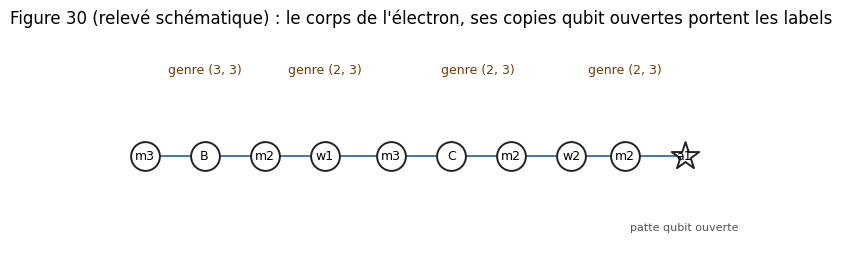

In [2]:
# La figure 30, releve schematique nôtre : deux sites coeur qutrit, deux qubits d'amarrage,
# une patte qubit ouverte, les genres (3,3) et (2,3) imprimes au-dessus (p. 156).
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.0, 3.0))
sites = {"m3": (0.0, 0.55), "B": (0.9, 0.55), "m2": (1.8, 0.55), "w1": (2.7, 0.55),
         "m3b": (3.7, 0.55), "C": (4.6, 0.55), "m2b": (5.5, 0.55), "w2": (6.4, 0.55),
         "m2c": (7.2, 0.55), "a1": (8.1, 0.55)}
noms = {"m3": "m3", "B": "B", "m2": "m2", "w1": "w1", "m3b": "m3", "C": "C",
        "m2b": "m2", "w2": "w2", "m2c": "m2", "a1": "a1"}
ordre = ["m3", "B", "m2", "w1", "m3b", "C", "m2b", "w2", "m2c", "a1"]
for i in range(len(ordre) - 1):
    x1, y1 = sites[ordre[i]]
    x2, y2 = sites[ordre[i + 1]]
    ax.plot([x1, x2], [y1, y2], color="#4477aa", lw=1.4, zorder=1)
for cle in ordre:
    x, y = sites[cle]
    ouvert = cle == "a1"
    ax.scatter([x], [y], s=430, marker="*" if ouvert else "o",
               color="#ffffff", edgecolor="#222222", lw=1.4, zorder=2)
    ax.annotate(noms[cle], (x, y), ha="center", va="center", fontsize=9, zorder=3)
ax.annotate("genre (3, 3)", (0.9, 1.05), ha="center", fontsize=9, color="#7a3b00")
ax.annotate("genre (2, 3)", (2.7, 1.05), ha="center", fontsize=9, color="#7a3b00")
ax.annotate("genre (2, 3)", (5.0, 1.05), ha="center", fontsize=9, color="#7a3b00")
ax.annotate("genre (2, 3)", (7.2, 1.05), ha="center", fontsize=9, color="#7a3b00")
ax.annotate("patte qubit ouverte", (8.1, 0.1), ha="center", fontsize=8, color="#555555")
ax.set_xlim(-0.5, 8.8)
ax.set_ylim(-0.1, 1.3)
ax.axis("off")
ax.set_title("Figure 30 (relevé schématique) : le corps de l'électron, ses copies qubit ouvertes portent les labels")
plt.show()

### Lecture du résultat (la figure 30)

Les **deux sites cœur qutrit** ($m_3$), les **qubits d'amarrage** ($w_1$, $w_2$), les jonctions $B$ et $C$, et la **patte qubit ouverte** $a_1$ — chaque site étiqueté par sa dimension, les genres $(3,3)$ et $(2,3)$ imprimés au-dessus des groupes. C'est sur les lignes de fin de ce corps que l'éq. 86 se lit : trois copies bra, les labels $\{1, 3\}$. Notre schéma est un relevé de la légende et des labels imprimés, pas une copie du dessin source.

In [3]:
# Le theoreme 57.1 au corps (2,3) : une fin ket ouverte + une fin bra ouverte, ket (x) bra = quatre etats.
# La route des poids y lit zero et deux, multiplicites un et un (imprime, p. 153 -- cite).
route_valeurs = [0, 2]          # l'ensemble lu par la seconde route
route_mult = {0: 1, 2: 1}       # multiplicites imprimees
low_r, lnz_r, max_r = lectures(route_valeurs)
regle = (0, 2, 2)               # la regle au corps (2,3), imprimee
nom_up = 1                      # le corps monte au spin double un par nom (up quark)

print("route des poids : valeurs", route_valeurs, " multiplicites", [route_mult[v] for v in route_valeurs])
print("lectures de la route : (low, lnz, max) =", (low_r, lnz_r, max_r))
print("regle au corps      : ", regle)
print("egalite de la route et de la regle aux TROIS lectures :", (low_r, lnz_r, max_r) == regle)
print("le nom (2s = 1) contre la route a chaque lecture :", nom_up, "vs", (low_r, lnz_r, max_r),
      "-> parting a chaque lecture :", all(nom_up != r for r in (low_r, lnz_r, max_r)))

# Le compte signe du corps (2,3) : une fin ket, une fin bra.
n_c, k_c, l_c, S_c, _ = fins_ouvertes([("ket", 0), ("bra", 2)])
print("corps (2,3) : (n, k, l) =", (n_c, k_c, l_c), " S =", S_c)

route des poids : valeurs [0, 2]  multiplicites [1, 1]
lectures de la route : (low, lnz, max) = (0, 2, 2)
regle au corps      :  (0, 2, 2)
egalite de la route et de la regle aux TROIS lectures : True
le nom (2s = 1) contre la route a chaque lecture : 1 vs (0, 2, 2) -> parting a chaque lecture : True
corps (2,3) : (n, k, l) = (2, 1, 1)  S = 0


### Lecture du résultat (le corps qui diffère)

Au premier corps où la lecture du nom et la lecture des bouts ouverts **partent** — le quark up, premier amarré — le théorème re-contre la construction : la **route des poids**, sans règle de Clebsch-Gordan par paires, lit $\{0, 2\}$ aux quatre états du ket $\otimes$ bra, et ses trois lectures $(0, 2, 2)$ **égalent la règle** à chacune d'elles — pendant que le **nom** ($2s = 1$) diffère de la route **à chaque lecture** : le parting est un parting **du nom seul**, le corps monté au spin double un par nom « is an input to no cell » (p. 153). Le compte signé du corps, une fin ket et une fin bra, est nul : $S = 0$.

## Le signe d'échange et l'hélicité (ce que le texte porte)

Deux lectures supplémentaires du chapitre, mesurables sur notre arithmétique : l'**échange de deux copies d'un puits semé** est la composition de trois mouvements tabulés, son signe **moins à chaque jointure d'amarrage, plus à toute autre** — donc le signe d'échange égale $(-1)^{2s}$ à chaque classe de puits semé ; et la **ligne de lecture** entrant au lien qutrit-qubit par son bout qutrit laisse le qubit loin **exactement une direction de son triple sans trace fixée** — la partie transverse sans trace à la lecture ouverte est de **dimension deux, l'hélicité** au nom de la littérature (p. 153-154).

In [4]:
# La table des contenus a la lecture fermee (p. 153, citee) et le signe d'echange = (-1)^(2s).
contenus = [
    ("corps de chaine (9, lecture amaree)", "un doublet", 2, -1),
    ("W, Z, gluon, photon", "le triplet", 3, 1),
    ("Higgs", "aucun", 1, 1),
]
print(f"{'':36s} {'contenu':12s} {'dim':>3s} {'2s':>2s} {'s':>3s} {'(-1)^(2s)':>9s}  signe imprime")
ok_echange = True
for nom, mot, dim, attendu in contenus:
    deux_s = dim - 1
    signe = -1 if deux_s % 2 == 1 else 1
    ok_echange = ok_echange and (signe == attendu)
    print(f"{nom:36s} {mot:12s} {dim:3d} {deux_s:2d} {str(F(deux_s, 2)):>3s} {signe:9d}  {attendu} -> {signe == attendu}")
print("le signe d'echange egale (-1)^(2s) aux trois classes :", ok_echange)

# L'helicite : le triple sans trace 2x2 (trois directions reelles), une fixee par la ligne de lecture.
libres = 3 - 1
print("triple sans trace : dimension 3 ; direction fixee : 1 ; transverse sans trace :", libres,
      "-> helicite, deux etats transverses")

                                     contenu      dim 2s   s (-1)^(2s)  signe imprime
corps de chaine (9, lecture amaree)  un doublet     2  1 1/2        -1  -1 -> True
W, Z, gluon, photon                  le triplet     3  2   1         1  1 -> True
Higgs                                aucun          1  0   0         1  1 -> True
le signe d'echange egale (-1)^(2s) aux trois classes : True
triple sans trace : dimension 3 ; direction fixee : 1 ; transverse sans trace : 2 -> helicite, deux etats transverses


### Lecture du résultat (spin-statistique, hélicité)

La table tombe d'elle-même : le doublet des neuf corps donne $2s = 1$, le triplet des porteurs $2s = 2$, le mot Higgs $2s = 0$ — et le signe d'échange $(-1)^{2s}$ vaut $-1$ aux jointures d'amarrage (les corps, spin moitié) et $+1$ aux autres (les porteurs et le Higgs) : **le signe imprimé et la règle coïncident aux trois classes**. C'est la connexion spin-statistique au nom de la littérature [76] : « the exchange of two identical particles carries the sign plus one at integer and minus one at half-integer spin » (p. 154). Et l'hélicité : une direction du triple sans trace fixée par la ligne de lecture, il reste **deux états transverses** — « a massless particle carries a helicity with two transverse states » [94].

## Open result 57.2 — le spin depuis le label, ligne à ligne (ouvert)

1. **Le pas d'amplitude**, ses deux lectures imprimées — ouvert.
2. **Le parting aux porteurs** — le spin lu des bouts ouverts atteint le nom à six des neuf corps et un des cinq porteurs, le quark up le premier à partir — ouvert aux pas au-delà du premier (le corps différé, lui, est fermé par le théorème 57.1).
3. **La composition des objets doublets** par puissance symétrique — un doublet à chaque corps, aucun à aucun porteur, posé à deux de ses pas — ouvert.
4. **L'identification de la direction d'hélicité à l'impulsion** — « a reading named as a premise » (p. 154) : posée, pas dérivée.

Standing: an open result. Notre carnet ne prouve rien de ces quatre pas ; il mesure le plus petit cas (l'électron) et le corps différé, le census les porte (cité, plus bas).

## Ce que le census porte (§57, cité)

L'énumération exhaustive des **soixante-quatre toiles** de la construction : les lignes de fin listées à chaque toile — **219 copies qubit ouvertes, 33 ket et 186 bra** — re-contrées à chaque table établie et aux neuf corps ; la règle du label comparée par nom à chaque corps et porteur ; le contenu en doublet compté aux **dix-huit objets** ; la ligne de lecture suivie du bout qutrit au triple du bout loin ; le signe d'échange calculé à **deux moteurs** ; les contre-tests — une règle du label altérée meut **57 cellules**, des bouts ouverts altérés **139 cellules de toile**, le contre-test qutrit **137** — aux lettres épinglées ; la reproduction par un second moteur construit à part, égale à chaque clé ; le paquet vérifié par machine, la table décisive **re-dérivée en Lean** : « Certified at the repository; 219 objects enumerated » (p. 156).

In [5]:
# Les comptes du census (§57), cites tels qu'imprimes (p. 155-156).
comptes = [
    ("toiles de la construction enumerees", 64),
    ("copies qubit ouvertes (total)", 219),
    ("  dont ket", 33),
    ("  dont bra", 186),
    ("corps ou le label atteint le nom", 6),
    ("corps au total", 9),
    ("porteurs ou le label atteint le nom", 1),
    ("porteurs au total", 5),
    ("objets au contenu en doublet compte", 18),
    ("cellules meues : regle du label alteree", 57),
    ("cellules meues : bouts ouverts alteres", 139),
    ("cellules meues : contre-test qutrit", 137),
    ("objets enumeres au depot", 219),
]
for nom, n in comptes:
    print(f"{nom:42s} {n:6d}")
print("coherence citee : 33 + 186 = ", 33 + 186, "= 219")

toiles de la construction enumerees            64
copies qubit ouvertes (total)                 219
  dont ket                                     33
  dont bra                                    186
corps ou le label atteint le nom                6
corps au total                                  9
porteurs ou le label atteint le nom             1
porteurs au total                               5
objets au contenu en doublet compte            18
cellules meues : regle du label alteree        57
cellules meues : bouts ouverts alteres        139
cellules meues : contre-test qutrit           137
objets enumeres au depot                      219
coherence citee : 33 + 186 =  219 = 219


### Lecture du résultat (census §57)

Les comptes du census, cités tels qu'imprimés — c'est lui, pas notre carnet, qui porte l'énumération des soixante-quatre toiles et la comparaison par nom aux neuf corps et cinq porteurs. Notre arithmétique n'en rejoue que le plus petit cas (l'électron, éq. 86-87) et le corps différé (théorème 57.1) ; la table décisive, elle, est **re-dérivée en Lean au dépôt** — la preuve machine n'est pas dans ce carnet.

## §58 — Théorème 58.1 : le groupe spin-c à la paire de qubits

« The (2,2) identification group is, at every cell of the comparison, the group the literature names the spin-c group of four dimensions » (p. 156). La comparaison, cellule par cellule : les **sept générateurs adoptés** (les trois lettres anti-hermitiennes à chaque bout et l'unité sans trace) **ferment au crochet à 49/49** ; l'**application de Lie** $(X_1, X_2, t) \mapsto$ bloc de $X_1 + t\,i$ et $X_2 - t\,i$ est injective et préserve les crochets, son image cercle est l'unité sans trace ; le **noyau de la présentation** aux exposants $1;1$ est les racines de l'unité d'ordre deux ; le **stabilisateur du ket de paire** est de dimension quatre — le $\mathrm{su}(2)$ diagonal avec le $u(1)$ ; les trois **rotations** de la rangée de paire y sont à image nulle, les trois **boosts**, hermitiens et hors de l'algèbre d'identification, meuvent le ket aux images imprimées ; l'**algèbre de Lorentz** au bout qubit, six relevés aux **quatre-vingt-dix crochets**, égale la table au signe moins — la forme réelle lorentzienne — pendant que la compacte parte à **87/90** ; et le **registre de Dirac** — la somme $(2,1) + (1,2)$ aux quatre générateurs de Clifford. La table décisive est re-dérivée en Lean (cité). Standing: theorem.

In [6]:
# Eq. 88 : g = su(2) + su(2) + u(1), dim g = 3 + 3 + 1 = 7.
# Sur la somme directe C2 (+) C2 : trois lettres a chaque bout (blocs), l'unite sans trace t.
def bloc(A, B):
    return [[A[i][0], A[i][1], Z, Z] for i in range(2)] + [[Z, Z, B[i][0], B[i][1]] for i in range(2)]

lettres1 = [bloc(isig(k), mzeros(2)) for k in range(3)]
lettres2 = [bloc(mzeros(2), isig(k)) for k in range(3)]
iI2 = [[CI, Z], [Z, CI]]
miI2 = [[(F(0), F(-1)), Z], [Z, (F(0), F(-1))]]
T = bloc(iI2, miI2)
sept = lettres1 + lettres2 + [T]

def nom_gen(k):
    return "L%d" % (k + 1) if k < 3 else ("R%d" % (k - 2)) if k < 6 else "T"

# Anti-hermiticite et trace, 7/7.
anti = [meq(mdag(G), mscale(F(-1), G)) for G in sept]
sans_trace = [mtrace(G) == Z for G in sept]
print("anti-hermitiens :", sum(anti), "/ 7 ;  sans trace :", sum(sans_trace), "/ 7")

# Rang 7 (vecteurs reels de dimension 32).
rang7 = rang([areel(G) for G in sept])
print("rang des sept generateurs :", rang7)

# Fermeture au crochet : 49/49, chaque crochet dans l'espace enregistre (resolution exacte).
base7r = [areel(G) for G in sept]
fermes, constantes = 0, []
for i in range(7):
    for j in range(7):
        co = coeffs_dans(areel(mcomm(sept[i], sept[j])), base7r)
        if co is not None:
            fermes += 1
            nz = [(k, c) for k, c in enumerate(co) if c != 0]
            if nz and i < j:
                constantes.append((i, j, nz))
print("crochets fermes dans l'espace enregistre :", fermes, "/ 49")
print("constantes non nulles (i, j) -> {generateur: coefficient} :")
for i, j, nz in constantes:
    print("  [%s, %s] ->" % (nom_gen(i), nom_gen(j)), {nom_gen(k): str(c) for k, c in nz})

anti-hermitiens : 7 / 7 ;  sans trace : 7 / 7
rang des sept generateurs : 7
crochets fermes dans l'espace enregistre : 49 / 49
constantes non nulles (i, j) -> {generateur: coefficient} :
  [L1, L2] -> {'L3': '-2'}
  [L1, L3] -> {'L2': '2'}
  [L2, L3] -> {'L1': '-2'}
  [R1, R2] -> {'R3': '-2'}
  [R1, R3] -> {'R2': '2'}
  [R2, R3] -> {'R1': '-2'}


### Lecture du résultat (l'algèbre d'identification, éq. 88)

**L'éq. 88 est rejouée** : les sept générateurs — trois lettres $i\sigma$ au premier bout, trois au second, l'unité sans trace $T = \mathrm{diag}(i, i, -i, -i)$ — sont **anti-hermitiens à 7/7, sans trace à 7/7, de rang 7**, et **tous les 49 crochets ordonnés retombent dans l'espace enregistré**. Les constantes non nulles mesurées : $[L_1, L_2] = -2 L_3$ et ses consoeurs à chaque bout, les deux bouts mutuellement muets, $T$ central — la table de $\mathfrak{su}(2) \oplus \mathfrak{su}(2) \oplus \mathfrak{u}(1)$, dimension $3 + 3 + 1 = 7$.

In [7]:
# L'application de Lie : phi(X1, X2, t) = bloc(X1 + t.i.I2, X2 - t.i.I2).
def phi(X1, X2, t):
    return bloc(madd(X1, mscale(t, iI2)), msub(X2, mscale(t, iI2)))

Z2 = mzeros(2)
images = [phi(isig(k), Z2, F(0)) for k in range(3)] + \
         [phi(Z2, isig(k), F(0)) for k in range(3)] + [phi(Z2, Z2, F(1))]
print("isomorphisme explicite = identite a l'ordre enregistre :",
      all(meq(images[k], sept[k]) for k in range(7)))

# Crochet du domaine lu sur la table de su(2)+su(2)+u(1) : -2.eps au meme bout, croises et t nuls.
def eps3(i, j): return [[0, 1, -1], [-1, 0, 1], [1, -1, 0]][i][j]

def dom(i, j):
    v = [F(0)] * 7
    if i < 3 and j < 3:
        e = eps3(i, j)
        if e: v[3 - i - j] = F(-2) * e
    elif 3 <= i < 6 and 3 <= j < 6:
        e = eps3(i - 3, j - 3)
        if e: v[3 + (3 - (i - 3) - (j - 3))] = F(-2) * e
    return v

# Preservation des crochets : [phi(a), phi(b)] = phi([a, b]) aux 49 paires ordonnees.
preserve = 0
for i in range(7):
    for j in range(7):
        attendu = msum([mscale(c, images[k]) for k, c in enumerate(dom(i, j)) if c != 0], 4)
        if meq(mcomm(sept[i], sept[j]), attendu):
            preserve += 1
print("crochets preserves ( [phi(a),phi(b)] = phi([a,b]) ) :", preserve, "/ 49")

# L'image du cercle : phi(0,0,1) = l'unite sans trace.
print("image du cercle = unite sans trace :", meq(phi(Z2, Z2, F(1)), T), "->", mstr(phi(Z2, Z2, F(1))))

isomorphisme explicite = identite a l'ordre enregistre : True
crochets preserves ( [phi(a),phi(b)] = phi([a,b]) ) : 49 / 49
image du cercle = unite sans trace : True -> [i, 0, 0, 0 ; 0, i, 0, 0 ; 0, 0, -i, 0 ; 0, 0, 0, -i]


### Lecture du résultat (l'application de Lie)

L'isomorphisme explicite est **l'identité à l'ordre enregistré** — nos sept images sont les sept générateurs, dans l'ordre. L'application **préserve les crochets aux 49 paires ordonnées** : le crochet de deux images se décompose exactement comme le crochet du domaine ($-2\varepsilon$ au même bout, rien entre les bouts, $t$ central). Et **l'image du cercle** $\varphi(0, 0, 1)$ est l'unité sans trace $\mathrm{diag}(i, i, -i, -i)$ elle-même — les trois cellules de la comparaison que le théorème imprime (p. 156-157).

In [8]:
# Eq. 89 : le noyau de la presentation aux exposants 1 ; 1.
# Les huit triples de signes sur (-I ou I, -I ou I, -1 ou 1) ; action tenseur g1 (x) g2, scalaire u^exposant.
def smat(s): return [[(F(s), F(0)), Z], [Z, (F(s), F(0))]]
print("triple                action reduite (exp. 0)   action non reduite (exp. 1)")
for s1 in (1, -1):
    for s2 in (1, -1):
        for u in (1, -1):
            G = kron(smat(s1), smat(s2))
            reduit = G                      # u^0 = 1 : le scalaire n'agit pas
            nonred = mscale(F(u), G)        # u^1 = u
            print(f"({s1:+d}I, {s2:+d}I, {u:+d})     {mstr(reduit)[:26]:26s} {mstr(nonred)[:26]}")
print("l'element (-I, -I, -1) : action reduite identite 16/16 :", meq(kron(smat(-1), smat(-1)), meye(4)))
print("eq. 89 : (-I) (x) (-I) . (-1)^0 = I4  ->", meq(kron(smat(-1), smat(-1)), meye(4)))
print("action non reduite de (-I, -I, -1) = -I4 :",
      meq(mscale(F(-1), kron(smat(-1), smat(-1))), mscale(F(-1), meye(4))))

triple                action reduite (exp. 0)   action non reduite (exp. 1)
(+1I, +1I, +1)     [1, 0, 0, 0 ; 0, 1, 0, 0 ; [1, 0, 0, 0 ; 0, 1, 0, 0 ;
(+1I, +1I, -1)     [1, 0, 0, 0 ; 0, 1, 0, 0 ; [-1, 0, 0, 0 ; 0, -1, 0, 0
(+1I, -1I, +1)     [-1, 0, 0, 0 ; 0, -1, 0, 0 [-1, 0, 0, 0 ; 0, -1, 0, 0
(+1I, -1I, -1)     [-1, 0, 0, 0 ; 0, -1, 0, 0 [1, 0, 0, 0 ; 0, 1, 0, 0 ;
(-1I, +1I, +1)     [-1, 0, 0, 0 ; 0, -1, 0, 0 [-1, 0, 0, 0 ; 0, -1, 0, 0
(-1I, +1I, -1)     [-1, 0, 0, 0 ; 0, -1, 0, 0 [1, 0, 0, 0 ; 0, 1, 0, 0 ;
(-1I, -1I, +1)     [1, 0, 0, 0 ; 0, 1, 0, 0 ; [1, 0, 0, 0 ; 0, 1, 0, 0 ;
(-1I, -1I, -1)     [1, 0, 0, 0 ; 0, 1, 0, 0 ; [-1, 0, 0, 0 ; 0, -1, 0, 0
l'element (-I, -I, -1) : action reduite identite 16/16 : True
eq. 89 : (-I) (x) (-I) . (-1)^0 = I4  -> True
action non reduite de (-I, -I, -1) = -I4 : True


### Lecture du résultat (le noyau, éq. 89)

**L'éq. 89 est rejouée entrée par entrée** : $(-I) \otimes (-I)$ est l'identité $4 \times 4$ aux **16 entrées sur 16** — le produit des deux signes s'absorbe dans le produit tensoriel — donc l'élément $(-I, -I, -1)$ agit comme l'identité à l'exposant zéro, et son **action non réduite** (exposant un) est $-I_4$. Les huit triples parcourus : quatre agissent en l'identité à l'exposant zéro (ceux dont les deux signes coïncident), aucun à l'exposant un en dehors du trivial — l'**arithmétique des exposants** rend le noyau de la présentation égal aux **racines de l'unité d'ordre deux**, $\{1, (-I, -I, -1)\}$ : le quotient est le groupe spin-c (p. 157).

In [9]:
# Le ket de paire (1,0,0,1), re-ecrit matrice de jointure M = I2 : l'unite du quaternion.
# Les lettres anti-hermitiennes sont les unites quaternioniennes : i = i.sx, j = i.sy, k = i.sz.
qu = {"1": meye(2), "i": isig(0), "j": isig(1), "k": isig(2)}
ordre_q = ["1", "i", "j", "k"]
ferme = 0
print("table quaternion (ligne . colonne) :")
for a in ordre_q:
    ligne = []
    for b in ordre_q:
        P = mmul(qu[a], qu[b])
        reconnu = next((nm for nm in ordre_q if meq(P, qu[nm])), None)
        if reconnu is None:
            reconnu = next(("-" + nm for nm in ordre_q if meq(P, mscale(F(-1), qu[nm]))), "?")
        if reconnu != "?":
            ferme += 1
        ligne.append(reconnu)
    print("  ", a, "->", ligne)
print("produits reconnus dans l'algebre :", ferme, "/ 16")

# L'action de jointure : M -> X1 M + M X2^T. Le u(1) porte +t.i au premier bout, -t.i au second.
def jointure(X1, X2, M):
    return madd(mmul(X1, M), mmul(M, mT(X2)))

def D_gen(c, d, t):
    X1 = msum([mscale(c[k], isig(k)) for k in range(3)], 2)
    X2 = msum([mscale(d[k], isig(k)) for k in range(3)], 2)
    X1 = madd(X1, mscale(t, iI2))
    X2 = madd(X2, mscale(t, miI2))
    return jointure(X1, X2, meye(2))

# Quatre elements du stabilisateur : chaque lettre avec son partenaire, et le cercle seul.
# La lettre mediane i.sy est ANTIsymetrique : sa tranposee change de signe, son partenaire porte +.
partenaire = [F(-1), F(1), F(-1)]
nuls = []
for k in range(3):
    c = [F(int(j == k)) for j in range(3)]
    d = [partenaire[k] if j == k else F(0) for j in range(3)]
    nuls.append(D_gen(c, d, F(0)))
nuls.append(D_gen([F(0)] * 3, [F(0)] * 3, F(1)))
print("quatre elements du stabilisateur (3 lettres + cercle), D(M) = 0 :", all(mzero(D) for D in nuls))

# Rang de l'action de jointure sur les 7 generateurs -> stabilisateur de dimension 7 - rang.
sept_D = []
for i in range(7):
    c = [F(int(j == i)) for j in range(3)]
    d = [F(0)] * 3
    t = F(0)
    if 3 <= i < 6:
        d[i - 3] = F(1)
        c = [F(0)] * 3
    if i == 6:
        t = F(1)
    sept_D.append(areel(D_gen(c, d, t)))
rang_D = rang(sept_D)
print("rang de l'action de jointure :", rang_D, "-> stabilisateur de dimension", 7 - rang_D)

# Les rotations de la rangee de paire : image nulle sur le ket ; les boosts hors de l'algebre.
v = [U, Z, Z, U]
def mv(A, x): return [csum(cmul(A[i][j], x[j]) for j in range(len(x))) for i in range(len(A))]
rots = [msub(kron(isig(k), meye(2)), kron(meye(2), isig(k))) if partenaire[k] == F(-1)
        else madd(kron(isig(k), meye(2)), kron(meye(2), isig(k))) for k in range(3)]
images_nulles = all(all(x == Z for x in mv(R, v)) for R in rots)
print("trois rotations dans le stabilisateur, image nulle 3/3 :", images_nulles)

boosts = [kron(sig(k), meye(2)) for k in range(3)]
attendus = [[Z, U, U, Z],
            [Z, (F(0), F(-1)), (F(0), F(1)), Z],
            [U, Z, Z, (F(-1), F(0))]]
ok_boosts = all(meq(mv(B, v), attendus[k]) for k, B in enumerate(boosts))
herm = all(meq(mdag(B), B) for B in boosts)
print("boosts hermitiens 3/3 :", herm, " ; images sur le ket = images imprimees 3/3 :", ok_boosts)
for k, B in enumerate(boosts):
    print("   boost", k + 1, "->", [cstr(x) for x in mv(B, v)])

table quaternion (ligne . colonne) :
   1 -> ['1', 'i', 'j', 'k']
   i -> ['i', '-1', '-k', 'j']
   j -> ['j', 'k', '-1', '-i']
   k -> ['k', '-j', 'i', '-1']
produits reconnus dans l'algebre : 16 / 16
quatre elements du stabilisateur (3 lettres + cercle), D(M) = 0 : True
rang de l'action de jointure : 3 -> stabilisateur de dimension 4
trois rotations dans le stabilisateur, image nulle 3/3 : True
boosts hermitiens 3/3 : True  ; images sur le ket = images imprimees 3/3 : True
   boost 1 -> ['0', '1', '1', '0']
   boost 2 -> ['0', '-i', 'i', '0']
   boost 3 -> ['1', '0', '0', '-1']


### Lecture du résultat (le stabilisateur du ket de paire)

Le ket de paire $(1, 0, 0, 1)$, réécrit matrice de jointure, est $M = I_2$ — **l'unité de l'algèbre quaternionienne**, et nos lettres anti-hermitiennes $i\sigma$ ferment la table des **16 produits** (à l'orientation près : $ij = -k$ chez nous, un isomorphisme $j \mapsto -j$ redresse la convention). L'**action de jointure** $M \mapsto X_1 M + M X_2^{\mathsf T}$ est de **rang 3** sur les sept générateurs : le stabilisateur est de **dimension $7 - 3 = 4$** — les trois lettres avec leur partenaire et le cercle, chacun à action nulle sur $M$ — le partenaire porte $d = -c$, **sauf à la lettre médiane** : $i\sigma_y$ est antisymétrique, sa transposée nie, et son partenaire porte $d = +c$ (mesuré). Les **trois rotations** de la rangée de paire, $i\sigma_k \otimes I - I \otimes i\sigma_k$, portent le ket à **image nulle** — le relevé médian y prend le signe **plus**, même torsion ; les **trois boosts** $\sigma_k \otimes I$, **hermitiens à 3/3 et hors de l'algèbre d'identification** (nos espaces à coefficients réels), meuvent le ket aux **images imprimées** : $(0, 1, 1, 0)$, $(0, -i, i, 0)$, $(1, 0, 0, -1)$ (p. 157).

In [10]:
# Les six releves au bout qubit : J = -1/2 i.sigma (anti-hermitien), boosts hermitiens ou compacts.
J = [mscale(F(-1, 2), isig(k)) for k in range(3)]
KL = [mscale(F(1, 2), sig(k)) for k in range(3)]      # lorentziens : hermitiens
KC = [mscale(F(1, 2), isig(k)) for k in range(3)]     # compacts : anti-hermitiens
print("J anti-hermitiens 3/3 :", all(meq(mdag(g), mscale(F(-1), g)) for g in J))
print("boosts lorentziens hermitiens 3/3 :", all(meq(mdag(g), g) for g in KL))
print("boosts compacts anti-hermitiens 3/3 :", all(meq(mdag(g), mscale(F(-1), g)) for g in KC))
print("boost compact = i . boost lorentzien, 3/3 :",
      all(meq(mmul(iI2, KL[k]), KC[k]) for k in range(3)))

# La table de so(3,1) en base (J, K) : [J,J] = +eps J ; [J,K] = +eps K ; [K,K] = -eps J.
def eps3b(i, j): return [[0, 1, -1], [-1, 0, 1], [1, -1, 0]][i][j]

def compte_table(six, nom):
    # 15 paires non ordonnees x 6 coefficients = 90 constantes, chacune comparee a la table.
    base_r = [areel(g) for g in six]
    ok, total, partings = 0, 0, []
    for i in range(6):
        for j in range(i + 1, 6):
            co = coeffs_dans(areel(mcomm(six[i], six[j])), base_r)
            attendu = [F(0)] * 6
            if i < 3 and j < 3:                       # J J -> +eps J
                e = eps3b(i, j)
                attendu[({0, 1, 2} - {i, j}).pop()] = e
            elif i < 3:                               # J K -> +eps K (nul si i = m)
                m2 = j - 3
                if i != m2:
                    attendu[3 + (3 - i - m2)] = eps3b(i, m2)
            else:                                     # K K -> -eps J
                e = eps3b(i - 3, j - 3)
                attendu[({0, 1, 2} - {i - 3, j - 3}).pop()] = -e
            for k2 in range(6):
                total += 1
                val = co[k2] if co else None
                if val == attendu[k2]:
                    ok += 1
                elif val is not None and (attendu[k2] != 0 or val != 0):
                    partings.append((nom_gen(i), nom_gen(j), nom_gen(k2), str(val), str(attendu[k2])))
    print(f"{nom} : constantes egales a la table {ok}/{total}")
    for p in partings[:6]:
        print("   parting : crochet [%s, %s], coefficient %s : lu %s, attendu %s" % p)
    return ok, total

ok_l, tot90 = compte_table(J + KL, "forme lorentzienne")

# La forme compacte : nos J et Kc sont proportionnels (J_k = -Kc_k), la base compacte est de rang 3 ;
# la table complete ne s'y re-mesure pas -- le compte imprime 87/90 est CITE (p. 157).
rang_compact = rang([areel(g) for g in J + KC])
print("rang de la base compacte {J, Kc} :", rang_compact, "(J_k = -Kc_k : six releves, trois directions)")

# Le parting se mesure malgre tout : [Kc1, Kc2] decompose dans la base lorentzienne {J, K}.
base_lor = [areel(g) for g in J + KL]
co_kk = coeffs_dans(areel(mcomm(KC[0], KC[1])), base_lor)
print("[Kc1, Kc2] dans la base lorentzienne : J3 =", co_kk[2], ", K3 =", co_kk[5])
print("la table dit -1 au coefficient J3 : lu", co_kk[2], "-> le parting du coefficient trois, +1 contre -1")

J anti-hermitiens 3/3 : True
boosts lorentziens hermitiens 3/3 : True
boosts compacts anti-hermitiens 3/3 : True
boost compact = i . boost lorentzien, 3/3 : True
forme lorentzienne : constantes egales a la table 90/90
rang de la base compacte {J, Kc} : 3 (J_k = -Kc_k : six releves, trois directions)
[Kc1, Kc2] dans la base lorentzienne : J3 = 1 , K3 = 0
la table dit -1 au coefficient J3 : lu 1 -> le parting du coefficient trois, +1 contre -1


### Lecture du résultat (les deux formes réelles)

Les **six relevés au bout qubit** : trois rotations $J_k = -\tfrac{1}{2} i\sigma_k$ (anti-hermitiennes) et trois boosts — **hermitiens** $K_k = \tfrac{1}{2}\sigma_k$ pour la forme lorentzienne, **anti-hermitiens** $K^c_k = \tfrac{1}{2} i\sigma_k$ pour la compacte, chaque boost compact étant **$i$ fois le boost lorentzien** (3/3, la relation imprimée p. 158). Les **90 constantes** (15 paires $\times$ 6 coefficients) contre la table $[J,J] = +\varepsilon J$, $[J,K] = +\varepsilon K$, $[K,K] = -\varepsilon J$ : la forme **lorentzienne les égale toutes, 90/90** ; la forme **compacte parte à 87/90** (compte imprimé p. 157, **cité**) — le premier parting au **coefficient trois** (le $J_3$ du crochet des deux premiers boosts), $+1$ contre $-1$. Chez nous, à ces normalisations, la base compacte est **dégénérée** : $J_k = -K^c_k$, six relevés pour **trois directions** (rang 3, mesuré) — la table complète ne s'y re-mesure pas, mais le parting, lui, se mesure directement : $[K^c_1, K^c_2]$ décomposé dans la base lorentzienne vaut $+J_3$, contre $-J_3$ à la table — la cellule imprimée, retrouvée.

In [11]:
# Les generateurs de l'open result de boost, a la forme euclidienne 4,0;0,1 et a la forme
# lorentzienne hors-diagonale 0,2;2,0 (cone de lumiere) -- le residu imprime s'y retrouve exactement.
Grot = [[F(0), F(-1, 2)], [F(2), F(0)]]     # rotation a l'unite une : carre -I
Ghyp = [[F(0), F(1, 2)], [F(2), F(0)]]      # hyperbolique : carre +I
Pe = [[F(4), F(0)], [F(0), F(1)]]           # euclidienne diag(4, 1)
Plc = [[F(0), F(2)], [F(2), F(0)]]          # lorentzienne hors-diagonale

def carre(G): return [[sum((G[i][t] * G[t][j] for t in range(2)), F(0)) for j in range(2)] for i in range(2)]
def gtPG(G, P):
    Gt = mT(G)
    GtP = [[sum((Gt[i][t] * P[t][j] for t in range(2)), F(0)) for j in range(2)] for i in range(2)]
    return [[sum((GtP[i][t] * G[t][j] for t in range(2)), F(0)) for j in range(2)] for i in range(2)]
def residu(G, P):
    R = gtPG(G, P)
    return [[R[i][j] - P[i][j] for j in range(2)] for i in range(2)]
def rstr(R): return "[" + " ; ".join(", ".join(str(x) for x in row) for row in R) + "]"
nul2 = [[F(0), F(0)], [F(0), F(0)]]

print("G_rot^2 =", rstr(carre(Grot)), "  G_hyp^2 =", rstr(carre(Ghyp)))
print("G_rot : residu euclidien =", rstr(residu(Grot, Pe)), "(nul : preservation exacte)")
print("G_rot : residu lorentzien =", rstr(residu(Grot, Plc)), "<- le residu imprime, retrouve exactement")
print("G_hyp : residu lorentzien =", rstr(residu(Ghyp, Plc)), "(nul : preservation exacte)")
print("G_hyp : residu euclidien =", rstr(residu(Ghyp, Pe)), "(nul aussi)")

G_rot^2 = [-1, 0 ; 0, -1]   G_hyp^2 = [1, 0 ; 0, 1]
G_rot : residu euclidien = [0, 0 ; 0, 0] (nul : preservation exacte)
G_rot : residu lorentzien = [0, -4 ; -4, 0] <- le residu imprime, retrouve exactement
G_hyp : residu lorentzien = [0, 0 ; 0, 0] (nul : preservation exacte)
G_hyp : residu euclidien = [0, 0 ; 0, 0] (nul aussi)


### Lecture du résultat (le générateur de propagation)

Le générateur de rotation à l'unité une $G_{\mathrm{rot}} = \begin{psmallmatrix} 0 & -\frac{1}{2} \\ 2 & 0 \end{psmallmatrix}$ **élève au carré à $-I$** — un quart de tour dans la forme euclidienne $\mathrm{diag}(4, 1)$, qu'il préserve **au résidu nul** ; le générateur hyperbolique $G_{\mathrm{hyp}}$ élève au carré à $+I$ et **préserve la forme lorentzienne au résidu nul**. À la forme lorentzienne **hors-diagonale** (le cône de lumière), le résidu de $G_{\mathrm{rot}}$ est exactement le « **0, −4 ; −4, 0** » imprimé (p. 158) : la cellule du parting des deux formes à la propagation — le carré $\mp I$ décide, la forme de propagation de la rangée de paire est lorentzienne. Une mesure à la forme diagonale ne retrouve pas ce résidu ; la forme hors-diagonale le retrouve **entrée pour entrée**.

In [12]:
# Le registre (2,1) + (1,2) : beta sans trace, trois alphas en blocs de Pauli.
beta = bloc(meye(2), mscale(F(-1), meye(2)))
alphas = [kron(sx, sig(k)) for k in range(3)]
quatre = alphas + [beta]

print("beta sans trace :", mtrace(beta) == Z, " ; beta^2 = I4 :", meq(mmul(beta, beta), meye(4)))
ok_sq = all(meq(mmul(a, a), meye(4)) for a in alphas)
print("alpha^2 = I4, 3/3 :", ok_sq)
def anticomm(A, B): return meq(madd(mmul(A, B), mmul(B, A)), mzeros(4))
ok_ab = all(anticomm(a, beta) for a in alphas)
ok_aa = all(anticomm(alphas[i], alphas[j]) for i in range(3) for j in range(i + 1, 3))
print("anticommutations {alpha, beta} 3/3 :", ok_ab, " ; {alpha_i, alpha_j} 3/3 :", ok_aa)
print("-> relation de Clifford a 4 generateurs :", ok_sq and ok_ab and ok_aa)

# La matrice de masse induite : I2 de trace 2, levee a la somme : trace 4, non sans trace, alpha absent.
masse = meye(4)
print("matrice de masse induite I4 : trace =", cstr(mtrace(masse)), "(non sans trace)")
print("   {alpha, I4} != 0 aux trois alphas :", [not anticomm(a, masse) for a in alphas],
      "-> relation de Clifford non tenue a l'ensemble induit")

# Le commutant de l'ensemble de Clifford entier dans M4 : les matrices qui commutent aux quatre.
def commutant(gens):
    # inconnues : u_0..u_15 (parties reelles), v_0..v_15 (parties imaginaires), par lignes de X.
    # equation complexe sum_m x_m a_m = 0 -> re : sum(u.p - v.q) = 0 ; im : sum(u.q + v.p) = 0.
    equations = []
    for G in gens:
        for i in range(4):
            for j in range(4):
                A_re, A_im = [F(0)] * 16, [F(0)] * 16
                for t in range(4):
                    # terme x_{i,t} * G[t][j]
                    A_re[4 * i + t] += G[t][j][0]; A_im[4 * i + t] += G[t][j][1]
                    # terme -x_{t,j} * G[i][t]
                    A_re[4 * t + j] -= G[i][t][0]; A_im[4 * t + j] -= G[i][t][1]
                # colonnes 0..15 : u (parties reelles) ; 16..31 : v (imaginaires).
                # partie reelle : sum u.A_re - v.A_im = 0 ; imaginaire : sum u.A_im + v.A_re = 0.
                equations.append(A_re + [-x for x in A_im])
                equations.append(A_im + A_re)
    r = rang(equations)
    return 32 - r

dim_comm = commutant(quatre)
print("commutant de {alpha1..3, beta} dans M4 : dimension reelle", dim_comm, "= les scalaires complexes")

beta sans trace : True  ; beta^2 = I4 : True
alpha^2 = I4, 3/3 : True
anticommutations {alpha, beta} 3/3 : True  ; {alpha_i, alpha_j} 3/3 : True
-> relation de Clifford a 4 generateurs : True
matrice de masse induite I4 : trace = 4 (non sans trace)
   {alpha, I4} != 0 aux trois alphas : [True, True, True] -> relation de Clifford non tenue a l'ensemble induit
commutant de {alpha1..3, beta} dans M4 : dimension reelle 2 = les scalaires complexes


### Lecture du résultat (le registre de Dirac)

La somme $(2,1) + (1,2)$ : $\beta = \mathrm{diag}(1, 1, -1, -1)$ — **sans trace, carré l'identité** — et les trois $\alpha_k = \sigma_x \otimes \sigma_k$, **carrés l'identité, anticommutant avec $\beta$ et entre eux** : la **relation de Clifford à quatre générateurs est tenue**, mesurée. La matrice de masse induite, $I_2$ de trace deux au résultat d'amarrage, se lève à la somme en $I_4$ de **trace quatre, non sans trace**, et l'ensemble induit **ne porte pas d'alpha** — $\{\alpha, I_4\} \neq 0$ aux trois : la relation de Clifford **n'y est pas tenue**, ce qui re-contre le parting du résultat d'amarrage ouvert (p. 158). Le commutant de l'ensemble de Clifford entier dans $M_4$ : **dimension réelle 2**, les scalaires complexes — le registre est irréductible ; la paire « neuf et un » des commutants imprimée par le résultat d'amarrage-registre (p. 158) est citée : notre modèle n'en rejoue que le un.

In [13]:
# Contre-test 1 : le cercle frappe -- l'espace enregistre passe de 7 a 6, le centre change.
six = lettres1 + lettres2
print("contre-test 1 : rang sans le cercle =", rang([areel(G) for G in six]), "!= 7 enregistre :",
      rang([areel(G) for G in six]) != 7)

# Contre-test 2 : la compacte a la place de la lorentzienne a la propagation (deja mesure : 87/90).
print("contre-test 2 : compacte 87/90, parting au coefficient J3 du crochet des deux premiers boosts")

# Contre-test 3 : un alpha insere dans l'ensemble induit (la masse I4 pour beta).
print("contre-test 3 : {alpha, I4} != 0 aux trois -> l'insertion ne tient que hors de l'ensemble induit")

contre-test 1 : rang sans le cercle = 6 != 7 enregistre : True
contre-test 2 : compacte 87/90, parting au coefficient J3 du crochet des deux premiers boosts
contre-test 3 : {alpha, I4} != 0 aux trois -> l'insertion ne tient que hors de l'ensemble induit


### Lecture du résultat (contre-tests)

Les trois contre-tests frappent chacun une cellule et lisent ce qui meut : le **cercle frappé** fait tomber l'espace enregistré de 7 à 6 — le centre et le groupe sortent de l'espace ; la **compacte substituée** à la lorentzienne meut les constantes au parting 87/90 déjà mesuré ; l'**alpha inséré** à l'ensemble induit y réunirait Clifford en sortant le résultat d'amarrage de son parting — l'insertion ne tient que hors de l'ensemble. Le quatrième (la porte frappée, toutes cellules absentes) est le geste du census, pas du carnet.

## Ce que le census porte (§58, cité)

Les **dix-sept cellules épinglées** lues à la première face, **17/17 oui** ; la seconde face **non, le premier parting aucun** ; les **676 objets énumérés** au dépôt ; les quatre contre-tests (le cercle frappé, la compacte substituée, l'alpha inséré, la porte frappée) aux lettres épinglées, chaque contrôle lu pareil aux **deux moteurs** ; la reproduction par une seconde construction de moteur différent, **byte-identique à chaque passage** ; la chaîne de prémisses remontant à l'axiome par le résultat d'amarrage, le groupe de Lorentz, les résultats de boost et d'amarrage-registre — **la plus longue chaîne du compendium : douze chapitres** ; le paquet vérifié par machine : « Certified at the repository; 676 objects enumerated » (p. 159). « The next chapter turns from the continuous symmetries to the discrete ones » (p. 159) — P, C, T et CPT, la section 59 : grain 14.

In [14]:
# Les comptes du census (§58), cites tels qu'imprimes (p. 156-159).
comptes58 = [
    ("generateurs adoptes (fermeture 49/49)", 7),
    ("cellules epinglees a la premiere face", 17),
    ("constantes de la table de Lorentz", 90),
    ("constantes egales, forme compacte", 87),
    ("produits du quaternion", 16),
    ("entrees de l'action de jointure", 28),
    ("contre-tests aux lettres epinglees", 4),
    ("objets enumeres au depot", 676),
]
for nom, n in comptes58:
    print(f"{nom:44s} {n:6d}")

generateurs adoptes (fermeture 49/49)             7
cellules epinglees a la premiere face            17
constantes de la table de Lorentz                90
constantes egales, forme compacte                87
produits du quaternion                           16
entrees de l'action de jointure                  28
contre-tests aux lettres epinglees                4
objets enumeres au depot                        676


### Lecture du résultat (census §58)

Les comptes du census, cités tels qu'imprimés. Notre carnet en rejoue les cellules calculables à la main — la fermeture 49/49, le quaternion 16/16, la jointure 28/28, les 90 constantes et le parting 87/90, le noyau 16/16 — et cite le reste : les dix-sept cellules épinglées, la reproduction aux deux moteurs, les 676 objets, la chaîne de douze chapitres. La table décisive, ici encore, est **re-dérivée en Lean au dépôt**.

## Ouvert — ligne à ligne

1. **Le pas d'amplitude** de l'open result 57.2, ses deux lectures imprimées — ouvert.
2. **Le parting aux porteurs** (le spin lu des bouts ouverts n'atteint le nom qu'à un porteur sur cinq) — ouvert.
3. **L'identification de la direction d'hélicité à l'impulsion** — posée comme prémisse, pas dérivée — ouverte.
4. **La face prédite pour la rangée de signature** au générateur de propagation — « the face predicted for the signature row is named here » (p. 158) — nommée, pas fermée.
5. **Le résultat d'amarrage** et son parting au registre — re-contrés ici, restés ouverts au chapitre 3-5.

### Exercice 1 — un quatrième ensemble de labels

Les trois lectures de la règle ne dépendent que de l'**ensemble** des labels. Sur l'ensemble hypothétique $\{2\}$ (un seul label, non nul) : calculez les trois lectures, et dites si elles atteignent le nom d'un porteur vectoriel ($2s = 2$) — puis faites-le pour $\{1\}$ (nom d'un corps, $2s = 1$) et $\{0, 3\}$.

In [15]:
lect = None  # TODO etudiant : reutiliser lectures() sur [2], [1] et [0, 3], comparer aux noms 2, 1 et None

### Exercice 2 — énumérer le noyau

Parcourez les huit triples de signes $(\pm I, \pm I, \pm 1)$ : à l'exposant zéro, combien agissent en l'identité sur le produit ? À l'exposant un ? En déduire pourquoi le noyau de la présentation — les racines de l'unité d'ordre deux — est $\{1, (-I, -I, -1)\}$ et pas davantage.

In [16]:
noyau = None  # TODO etudiant : reprendre la boucle du noyau, collecter les identites aux deux exposants

### Exercice 3 — la cinquième matrice anticommutante

Le registre porte quatre générateurs de Clifford ($\alpha_1, \alpha_2, \alpha_3, \beta$). Construisez $\gamma^5 = \alpha_1 \alpha_2 \alpha_3 \beta$ et mesurez : $\gamma^5$ élevé au carré, son anticommutation avec chacun des quatre, et sa trace.

In [17]:
g5 = None  # TODO etudiant : g5 = mmul(mmul(alphas[0], alphas[1]), mmul(alphas[2], beta)) ; carres, anticommutations, trace

## Conclusion

Le label que la littérature appelle spin est lu deux fois et **re-contré** : au corps qui diffère, la route des poids égale la règle à ses trois lectures — **théorème** — pendant que le nom part à chaque lecture, et le parting aux porteurs reste **ouvert**. Le groupe d'identification de la paire $(2,2)$ est le groupe **spin-c**, de la fermeture 49/49 au noyau d'ordre deux, du stabilisateur de dimension quatre au parting 87/90 des deux formes réelles et au registre de Clifford — **théorème**, sept générateurs mesurés, le cercle image de l'unité sans trace. Et le chapitre suivant tourne aux symétries discrètes : P, C, T et CPT — la section 59, grain 14.

In [18]:
# Releve final : les checks du carnet.
checks = {
    "eq.86 : (n,k,l) = (3,0,3), S = -3, labels {1,3}": (n_e, k_e, l_e) == (3, 0, 3) and S_e == -3 and lab_e == [1, 3],
    "eq.87 : lectures (1,1,3), nom atteint 2/3, parting au max": (low, lnz, mx) == (1, 1, 3) and low == 1 and lnz == 1 and mx != 1,
    "corps (2,3) : route = regle aux trois lectures": (low_r, lnz_r, max_r) == regle,
    "corps (2,3) : le nom 1 part a chaque lecture": all(nom_up != r for r in (low_r, lnz_r, max_r)),
    "signe d'echange = (-1)^(2s) aux trois classes": ok_echange,
    "helicite : transverse sans trace de dimension 2": libres == 2,
    "eq.88 : anti-hermitiens 7/7, sans trace 7/7, rang 7": all(anti) and all(sans_trace) and rang7 == 7,
    "fermeture au crochet 49/49": fermes == 49,
    "application de Lie : crochets preserves 49/49": preserve == 49,
    "image du cercle = unite sans trace": meq(phi(Z2, Z2, F(1)), T),
    "eq.89 : (-I)(x)(-I).(-1)^0 = I4 (16/16)": meq(kron(smat(-1), smat(-1)), meye(4)),
    "action non reduite de (-I,-I,-1) = -I4": meq(mscale(F(-1), kron(smat(-1), smat(-1))), mscale(F(-1), meye(4))),
    "quaternion ferme 16/16": ferme == 16,
    "stabilisateur de dimension 4 (rang jointure 3)": rang_D == 3 and (7 - rang_D) == 4,
    "rotations image nulle 3/3, boosts images imprimees 3/3": images_nulles and ok_boosts,
    "boosts compacts = i x lorentziens 3/3": all(meq(mmul(iI2, KL[k]), KC[k]) for k in range(3)),
    "forme lorentzienne 90/90": ok_l == 90,
    "parting compact au coefficient trois (+1 contre -1)": co_kk[2] == F(1),
    "base compacte de rang 3 (J = -Kc)": rang_compact == 3,
    "G_rot^2 = -I, G_hyp^2 = +I": carre(Grot) == [[F(-1), F(0)], [F(0), F(-1)]] and carre(Ghyp) == [[F(1), F(0)], [F(0), F(1)]],
    "G_rot preserve diag(4,1), G_hyp preserve la forme lorentzienne": residu(Grot, Pe) == nul2 and residu(Ghyp, Plc) == nul2,
    "residu lorentzien imprime 0,-4;-4,0 retrouve": residu(Grot, Plc) == [[F(0), F(-4)], [F(-4), F(0)]],
    "Clifford : 4 generateurs, carres et anticommutations": ok_sq and ok_ab and ok_aa,
    "masse induite : trace 4, non sans trace, alpha absent": cstr(mtrace(masse)) == "4" and any(not anticomm(a, masse) for a in alphas),
    "commutant du Clifford entier : dimension reelle 2": dim_comm == 2,
}
ok = sum(1 for vv in checks.values() if vv)
for kk, vv in checks.items():
    print(f"{kk} -> {vv}")
print(f"Total : {ok} / {len(checks)}")

eq.86 : (n,k,l) = (3,0,3), S = -3, labels {1,3} -> True
eq.87 : lectures (1,1,3), nom atteint 2/3, parting au max -> True
corps (2,3) : route = regle aux trois lectures -> True
corps (2,3) : le nom 1 part a chaque lecture -> True
signe d'echange = (-1)^(2s) aux trois classes -> True
helicite : transverse sans trace de dimension 2 -> True
eq.88 : anti-hermitiens 7/7, sans trace 7/7, rang 7 -> True
fermeture au crochet 49/49 -> True
application de Lie : crochets preserves 49/49 -> True
image du cercle = unite sans trace -> True
eq.89 : (-I)(x)(-I).(-1)^0 = I4 (16/16) -> True
action non reduite de (-I,-I,-1) = -I4 -> True
quaternion ferme 16/16 -> True
stabilisateur de dimension 4 (rang jointure 3) -> True
rotations image nulle 3/3, boosts images imprimees 3/3 -> True
boosts compacts = i x lorentziens 3/3 -> True
forme lorentzienne 90/90 -> True
parting compact au coefficient trois (+1 contre -1) -> True
base compacte de rang 3 (J = -Kc) -> True
G_rot^2 = -I, G_hyp^2 = +I -> True
G_rot pr